In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/nilotpaldhar/sales-dataset-200-rows-xlsx-sheet1/SQL_Sales_Dataset_200_Rows.xlsx - Sheet1.csv


# 1. Load a CSV File and Display Basic Info

In [2]:
import pandas as pd
import numpy as np

In [3]:
df = pd.read_csv(r"/kaggle/input/datasets/nilotpaldhar/sales-dataset-200-rows-xlsx-sheet1/SQL_Sales_Dataset_200_Rows.xlsx - Sheet1.csv")

In [4]:
print(df.head())

   order_id  customer_name  order_date   category sub_category  \
0      1000    Caleb Davis  2025-01-31   Clothing        Jeans   
1      1001  Misty Herrera  2025-05-05   Clothing        Jeans   
2      1002      Rick Soto  2025-06-09   Clothing        Shoes   
3      1003      Sean Haas  2025-02-27  Furniture         Desk   
4      1004       Ann Hall  2025-06-01  Furniture      Cabinet   

     product_name  quantity  unit_price  total_price region  
0       Jeans Try         2        1197         2394   West  
1       Jeans New         9        1509        13581  South  
2        Shoes Us         5        1046         5230   East  
3    Desk Section        10         292         2920  South  
4  Cabinet Center         2         548         1096  North  


In [5]:
print("--- Info ---")
df.info()

--- Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   order_id       200 non-null    int64 
 1   customer_name  200 non-null    object
 2   order_date     200 non-null    object
 3   category       200 non-null    object
 4   sub_category   200 non-null    object
 5   product_name   200 non-null    object
 6   quantity       200 non-null    int64 
 7   unit_price     200 non-null    int64 
 8   total_price    200 non-null    int64 
 9   region         200 non-null    object
dtypes: int64(4), object(6)
memory usage: 15.8+ KB


In [6]:
print("Dataset Shape:", df.shape)

Dataset Shape: (200, 10)


In [7]:
print("Summary Statistics")
print(df.describe())

Summary Statistics
          order_id    quantity   unit_price   total_price
count   200.000000  200.000000   200.000000    200.000000
mean   1099.500000    4.910000  2421.495000  12100.535000
std      57.879185    3.017853  1464.016187  10915.548067
min    1000.000000    1.000000    79.000000     79.000000
25%    1049.750000    2.000000  1120.000000   3060.000000
50%    1099.500000    5.000000  2373.500000   8912.000000
75%    1149.250000    7.000000  3541.750000  19350.750000
max    1199.000000   10.000000  4997.000000  47940.000000


# 2. Handle Missing Values and Duplicates

In [8]:
print("Duplicate rows before:", df.duplicated().sum())

Duplicate rows before: 0


In [9]:
df = df.drop_duplicates()

In [10]:
print("\nMissing values per column:\n", df.isnull().sum())


Missing values per column:
 order_id         0
customer_name    0
order_date       0
category         0
sub_category     0
product_name     0
quantity         0
unit_price       0
total_price      0
region           0
dtype: int64


In [11]:
df = df.dropna()

In [12]:
print("\nMissing values after cleaning:\n", df.isnull().sum())


Missing values after cleaning:
 order_id         0
customer_name    0
order_date       0
category         0
sub_category     0
product_name     0
quantity         0
unit_price       0
total_price      0
region           0
dtype: int64


# 3. Group Data by Category and Find Total Revenue

In [13]:
category_revenue = (
    df.groupby('category')['total_price']
    .sum()
    .reset_index()
    .rename(columns={'total_price': 'total_revenue'})
    .sort_values(by='total_revenue', ascending=False)
)

print(category_revenue)

      category  total_revenue
2    Furniture         714399
3      Grocery         672147
1  Electronics         549302
0     Clothing         484259


# 4. Sort Data by Multiple Columns

In [14]:
sorted_df = df.sort_values(
    by=['category', 'total_price'], 
    ascending=[True, False]
)

print(sorted_df[['order_id', 'category', 'product_name', 'quantity', 'total_price']].head(10))

     order_id  category    product_name  quantity  total_price
168      1168  Clothing      Jeans Card        10        44620
59       1059  Clothing      Shirt Look         6        28764
157      1157  Clothing     Jacket Song         7        27405
180      1180  Clothing    Jacket Heart         6        25710
82       1082  Clothing  Jacket Realize         7        24402
42       1042  Clothing       Shoes Far         7        24115
171      1171  Clothing      Shoes Each         8        23216
128      1128  Clothing    Jacket Image         8        22576
62       1062  Clothing      Shoes Care         7        22456
99       1099  Clothing    Jeans Family         5        22095


--- Correlation Matrix Table ---
             quantity  unit_price  total_price
quantity         1.00        0.05         0.66
unit_price       0.05        1.00         0.67
total_price      0.66        0.67         1.00


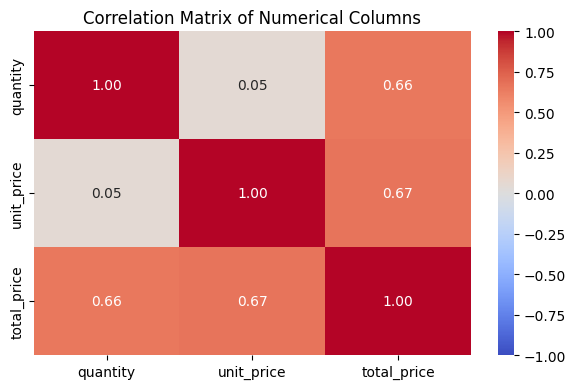

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns


corr_matrix = df[['quantity', 'unit_price', 'total_price']].corr()

print("--- Correlation Matrix Table ---")
print(corr_matrix.round(2))

plt.figure(figsize=(6, 4))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", vmin=-1, vmax=1)
plt.title('Correlation Matrix of Numerical Columns')
plt.tight_layout()
plt.show()